# Laboratorio di Analisi Numerica
## Lezione 3

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
13-14 ottobre 2026

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione usa `LinearAlgebra`, incluso nella libreria standard di Julia, e il pacchetto grafico `Plots`. Se `Plots` non è ancora installato, eseguite una sola volta `using Pkg; Pkg.add("Plots")` in una cella, quindi riavviate il kernel.

Eseguite le celle dall'alto verso il basso. Le celle degli esercizi sono da completare; le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite. Le funzioni fornite nelle lezioni precedenti e necessarie qui vengono riportate anche in questo notebook.

In [1]:
using LinearAlgebra
using Plots

## 1. Sottomatrici e determinanti

Utilizzando l'operatore `:` (*range operator*), in Julia è possibile selezionare un'intera sottomatrice di una matrice. Per indicizzare si usano le parentesi quadre:

In [2]:
A = [1 2 3; 4 5 6; 7 8 9]

3×3 Matrix{Int64}:
 1  2  3
 4  5  6
 7  8  9

In [3]:
A[1:2, 2:3]

2×2 Matrix{Int64}:
 2  3
 5  6

In [4]:
A[2:end, 1:end-2]

2×1 Matrix{Int64}:
 4
 7

In [5]:
A[1:end, 1:end]

3×3 Matrix{Int64}:
 1  2  3
 4  5  6
 7  8  9

In [6]:
A[1, :]

3-element Vector{Int64}:
 1
 2
 3

La sintassi `a:b` seleziona tutte le righe/colonne comprese tra `a` e `b` (estremi inclusi). Il valore `end` viene sostituito con il massimo indice disponibile lungo quella dimensione. Il solo `:` è un'abbreviazione per `1:end`.

**Julia:** un indice scalare elimina la dimensione corrispondente: `A[1, :]` restituisce un vettore monodimensionale, mentre `A[1:1, :]` mantiene una matrice con una sola riga. Analogamente, `A[2:end, 1:end-2]` è una matrice $2 \times 1$, perché entrambi gli indici sono intervalli.

Possiamo anche assegnare un valore a una sottomatrice selezionata in questo modo. La matrice identità si costruisce con `Matrix{Int}(I, 2, 2)` (qui `A` contiene interi):

In [7]:
A[1:2, 1:2] = Matrix{Int}(I, 2, 2)
A

3×3 Matrix{Int64}:
 1  0  3
 0  1  6
 7  8  9

Ovviamente le dimensioni devono essere compatibili: non posso selezionare una sottomatrice $2 \times 2$ e assegnarle il valore `Matrix{Int}(I, 3, 3)`!

La seguente funzione restituisce la *matrice minore* di $(i,j)$ in $A$, cioè la matrice che si ottiene eliminando la $i$-esima riga e la $j$-esima colonna di $A$.

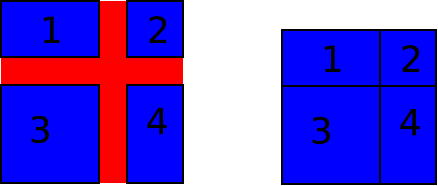

Matrice minore: si eliminano la riga i e la colonna j (figura della dispensa originale).

In [8]:
function minor(A, i, j)
    X = A[1:i-1, 1:j-1]
    Y = A[1:i-1, j+1:end]
    Z = A[i+1:end, 1:j-1]
    W = A[i+1:end, j+1:end]
    B = [X Y; Z W]
    return B
end

minor (generic function with 1 method)

Abbiamo già visto che se `X, Y, Z, W` sono numeri, la riga di codice `B = [X Y; Z W]` crea la matrice

$$
\begin{bmatrix} X & Y \\ Z & W \end{bmatrix}.
$$

Ora vediamo che la stessa sintassi funziona anche se `X, Y, Z, W` sono matrici di dimensioni compatibili e crea la matrice formata accostando i quattro blocchi.

### Esercizio 1

Creare una funzione `mydet(A)` che restituisca il determinante di una matrice quadrata $A$ utilizzando la formula di Laplace sulla prima riga, cioè

$$
\det(A)=A_{11}\det A^{(11)}-A_{12}\det A^{(12)}+A_{13}\det A^{(13)}-\dots+(-1)^{n+1}A_{1n}\det A^{(1n)},
$$

dove $A_{ij}$ è l'elemento di $A$ nella posizione $(i,j)$ e $A^{(ij)}$ è la matrice minore di $A$ rispetto a $(i,j)$.

**Suggerimento:** la funzione può essere *ricorsiva*, cioè chiamare se stessa al suo interno. Fate attenzione: bisogna definire un caso base!

Poi testarla su alcune matrici, confrontandola con la funzione `det` di Julia, fornita da `LinearAlgebra`, per esempio le matrici di Vandermonde `V = vander(1:2)`, `V = vander(1:3)`, `V = vander(1:4)`, …

Julia non fornisce `vander` nella libreria standard. Definiamo qui una funzione con la stessa convenzione di MATLAB: le potenze sono in ordine decrescente, quindi $V_{ij}=x_i^{n-j}$. Usiamo entrate in virgola mobile, come nelle matrici MATLAB originali, per evitare calcoli e overflow con interi a precisione fissa.

In [9]:
function vander(x)
    n = length(x)
    return [float(x[i])^(n-j) for i = 1:n, j = 1:n]
end

vander(1:3)

3×3 Matrix{Float64}:
 1.0  1.0  1.0
 4.0  2.0  1.0
 9.0  3.0  1.0

In [10]:
# Scrivete qui la funzione mydet(A) e i test richiesti
# Per esempio, dopo aver definito mydet:
# V = vander(1:4)
# @show mydet(V) det(V)

### Esercizio 2 (facoltativo)

La seguente funzione è equivalente a `minor(A, i, j)`. Come funziona?

**Suggerimento:** osservate cosa succede eseguendo `A[v, w]`, dove `v` e `w` sono vettori contenenti interi.

**Julia:** il punto e virgola in `[1:i-1; i+1:size(A, 1)]` concatena i due intervalli in un unico vettore di indici; uno spazio li affiancherebbe come colonne, richiedendo lunghezze uguali.

In [11]:
function minor2(A, i, j)
    B = A[[1:i-1; i+1:size(A, 1)], [1:j-1; j+1:size(A, 2)]]
    return B
end

minor2 (generic function with 1 method)

In [12]:
# Inserite qui gli esperimenti per capire come funziona minor2

## 2. Tempi di calcolo

La macro `@elapsed` misura il tempo necessario a eseguire un'espressione o un blocco di istruzioni e restituisce il tempo in secondi. Sostituisce la coppia di comandi MATLAB `tic` e `toc`.

Per riprodurre l'esempio, riportiamo la funzione `myexp2` della lezione 1:

In [13]:
function myexp2(x, n)
    t = 1.0
    a = 1.0
    for k = 1:n
        t = t * x / k
        a = a + t
    end
    return a
end

myexp2 (generic function with 1 method)

Julia compila le funzioni alla prima chiamata per i tipi di argomenti usati. Prima di misurare, eseguiamo quindi una chiamata preliminare con gli stessi tipi, per non includere il costo della compilazione nel tempo dell'algoritmo.

In [14]:
myexp2(10.0, 500)  # chiamata preliminare

t = @elapsed begin
    x = 10.0
    myexp2(x, 500)
end

t

7.4751e-5

Le istruzioni precedenti salvano in `t` il tempo necessario a eseguire le due righe nel blocco `begin ... end`.

La seguente funzione disegna un grafico del tempo impiegato per calcolare i determinanti delle matrici `vander(1:n)` con `n = 1:7`. Dopo aver completato l'esercizio 1, eseguite la chiamata a `plottimes()`.

Per tempi molto brevi, ripetete le misure: il carico del calcolatore e la gestione della memoria possono introdurre oscillazioni.

In [15]:
function plottimes()
    n = 7
    tempi = zeros(n)  # prepara un vettore con i tempi, inizialmente tutti zero
    mydet(vander(1:2))  # chiamata preliminare, fuori dalla misura
    for i = 1:n
        A = vander(1:i)  # la matrice viene generata prima di @elapsed: perché?
        tempi[i] = @elapsed mydet(A)
    end
    return plot(1:n, tempi; label="mydet", xlabel="n", ylabel="tempo (s)")
end

plottimes (generic function with 1 method)

In [16]:
# plottimes()  # togliete # dopo aver definito mydet

I tempi di calcolo crescono molto velocemente: la crescita fattoriale rende la funzione rapidamente impraticabile all’aumentare di $n$. I tempi effettivi dipendono dal calcolatore e dall’implementazione. Difatti, con questo algoritmo, per calcolare un determinante di dimensione $n$ dobbiamo calcolarne $n$ di dimensione $n-1$; quindi vale

$$
\operatorname{tempo}(n) \approx n\cdot\operatorname{tempo}(n-1),
$$

da cui $\operatorname{tempo}(n)\approx n!\cdot\operatorname{tempo}(1)$. Il nostro algoritmo quindi non è adatto a calcolare il determinante in modo efficiente.

## 3. Determinante con l'eliminazione di Gauss

### Esercizio 3

Scrivete una funzione `mydet2(A)` che restituisca il determinante utilizzando l'eliminazione di Gauss. Suggerimenti:

- Utilizzate espressioni del tipo `A[i, :] = A[i, :] + A[j, :]` per sommare due righe di una matrice, invece di scrivere un ciclo `for`.
- Per ora, ignorate il fatto che i pivot possono essere zero; se incontrate un pivot nullo, terminate con un messaggio di errore, usando `error("ho incontrato un pivot nullo")`.
- Per controllare che tutto vada bene, in una prima fase fatevi scrivere a schermo il valore di `A` dopo ogni passo di eliminazione di Gauss, usando `display(A)`.

**Julia:** modificare gli elementi di una matrice ricevuta come argomento modifica anche la matrice del chiamante. Per lavorare su una copia e consentire divisioni anche quando l'input contiene interi, iniziate la funzione con `A = float.(A)`: questa istruzione crea una nuova matrice con entrate in virgola mobile. Scrivere soltanto `B = A` non crea una copia. Se `A` è già una matrice in virgola mobile, si può invece usare `A = copy(A)`.

In [17]:
# Scrivete qui la funzione mydet2(A) e i primi test

### Esercizio 4

Disegnare un grafico che confronti i tempi di calcolo di `mydet`, `mydet2` e `det`, utilizzando la scala logaritmica su entrambi gli assi. Con `Plots` si usa `plot(...; xscale=:log10, yscale=:log10)`; aggiungete le altre curve con `plot!`.

Riportate sullo stesso grafico anche la curva di riferimento $y=n^3$. La scala log-log permette di confrontare tempi su scale molto diverse e di studiare la crescita rispetto alla dimensione $n$.

Qual è la pendenza della retta che corrisponde a $y=n^3$ nel grafico log-log? Come potete determinare dal grafico che `mydet2` richiede $O(n^3)$ operazioni mentre `mydet` è asintoticamente più costoso? La funzione `det` di Julia dovrebbe essere anch'essa cubica, ma il suo comportamento è più complicato da determinare per via delle ottimizzazioni usate; i tempi esatti dipendono fortemente dall'architettura del calcolatore.

Prima di misurare, effettuate una chiamata preliminare a ciascuna funzione con gli stessi tipi di argomenti. Disattivate le stampe usate per controllare l'eliminazione: altrimenti misurerete anche il tempo necessario a visualizzare le matrici. Limitate `mydet` a dimensioni piccole, per esempio fino a $n=7$; per `mydet2` e `det` potete provare dimensioni maggiori. Per tracciare $n^3$ su un vettore di dimensioni `ns`, usate `ns.^3`.

In [18]:
# Scrivete qui il confronto dei tempi in scala logaritmica

### Esercizio 5

Testate la funzione `mydet2` su alcune matrici per cui dovrebbe generare un errore a causa del pivot nullo. Per esempio, generate usando `rand(10, 10)` una matrice $10\times 10$ in cui tutte le entrate sono casuali, tranne la nona riga che è la somma delle otto righe precedenti. Cosa succede? Incontrate effettivamente un errore? Perché?

**Julia:** `sum(B; dims=1)` somma lungo la prima dimensione e restituisce una matrice con una sola riga; `vec` la converte in un vettore, come quello selezionato da `A[9, :]`. Senza `dims`, `sum(B)` somma invece tutti gli elementi di `B`.

In [19]:
# Scrivete qui le matrici di prova e gli esperimenti sui pivot nulli

### Esercizio 6 (facoltativo)

Scrivete una funzione che scambi opportunamente le righe quando incontra un pivot nullo, in modo da poter continuare l'algoritmo. Cosa succede al determinante quando scambio due righe?

Testate la funzione su alcune matrici, per esempio `A = vander(1:10)`, confrontandola con `det` di Julia.

In [20]:
# Scrivete qui la funzione con scambio di righe (mydet3) e i test richiesti